# AVIP 2026 — Task 2: Spam SMS Classifier

**Track:** AI/ML Engineering  
**Task:** Spam SMS / Email Classifier (SMS dataset)  
**Model:** TF-IDF + Multinomial Naive Bayes  
**Dataset:** [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)

**Note:** This model is trained on English SMS messages. It is not independently validated on emails or messages in other languages.

## 1. Import libraries and set up folders

In [1]:
import io
import json
import zipfile
import urllib.request
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

SEED = 42
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
print('Output folder:', OUT.resolve())

Output folder: /content/outputs


## 2. Download and inspect the dataset

The dataset is downloaded from the UCI Machine Learning Repository. The original labels are `ham` (legitimate) and `spam`.

In [2]:
url = 'https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip'
with urllib.request.urlopen(url, timeout=120) as response:
    archive_bytes = response.read()

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    print('Archive entries:', archive.namelist())
    with archive.open('SMSSpamCollection') as file:
        df = pd.read_csv(file, sep='\t', header=None,
                         names=['label', 'message'], encoding='utf-8')

print('Original dataset shape:', df.shape)
display(df.head())
print('Original class counts:')
print(df['label'].value_counts())

Archive entries: ['SMSSpamCollection', 'readme']
Original dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Original class counts:
label
ham     4825
spam     747
Name: count, dtype: int64


## 3. Clean the data

Remove missing entries and duplicate messages before the train/test split, so identical messages cannot appear in both sets. Keep the original SMS text for TF-IDF to process. This is a simple baseline, not a guarantee against near-duplicate messages.

In [3]:
df = df.dropna(subset=['label', 'message']).copy()
df['message'] = df['message'].astype(str).str.strip()
df = df[df['message'].str.len() > 0]
df = df[df['label'].isin(['ham', 'spam'])]

# Messages with the same text are treated as duplicates (keep the first occurrence).
duplicates = int(df.duplicated(subset=['message']).sum())
df = df.drop_duplicates(subset=['message']).reset_index(drop=True)
df['target'] = df['label'].map({'ham': 0, 'spam': 1}).astype(int)

print('Removed duplicate messages:', duplicates)
print('Cleaned dataset shape:', df.shape)
print('Cleaned class counts:')
print(df['label'].value_counts())
display(df.head())

df[['label', 'message']].head(20).to_csv(OUT / 'dataset_sample.csv', index=False)

Removed duplicate messages: 414
Cleaned dataset shape: (5158, 3)
Cleaned class counts:
label
ham     4516
spam     642
Name: count, dtype: int64


,label,message,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 4. Split the data

The cleaned dataset is divided into **80% training and 20% testing**, using a fixed random seed and stratification to preserve the class balance. The test set is reserved for final evaluation.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df['message'], df['target'], test_size=0.20, random_state=SEED,
    stratify=df['target']
)
print('Training messages:', len(X_train))
print('Test messages:', len(X_test))
print('Train label counts:', y_train.value_counts().to_dict())
print('Test label counts:', y_test.value_counts().to_dict())

Training messages: 4126
Test messages: 1032
Train label counts: {0: 3612, 1: 514}
Test label counts: {0: 904, 1: 128}


## 5. Train the model

**TF-IDF** converts messages into numerical features. **Multinomial Naive Bayes** learns to classify those features as spam or ham. Both steps are stored in one pipeline so preprocessing is automatically applied when predicting new messages.

In [5]:
model = Pipeline([
    ('tfidf', TfidfVectorizer(lowercase=True, stop_words='english',
                              ngram_range=(1, 2), min_df=2)),
    ('classifier', MultinomialNB(alpha=0.5))
])
model.fit(X_train, y_train)
print('Model trained successfully.')

Model trained successfully.


## 6. Evaluate on the Held-Out Test Set

In [11]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = {
    'accuracy': float(accuracy_score(y_test, y_pred)),
    'precision_spam': float(precision_score(y_test, y_pred, zero_division=0)),
    'recall_spam': float(recall_score(y_test, y_pred, zero_division=0)),
    'f1_spam': float(f1_score(y_test, y_pred, zero_division=0)),
    'train_count': int(len(X_train)),
    'test_count': int(len(X_test)),
    'original_count': 5572,
    'cleaned_count': int(len(df)),
    'model': 'TF-IDF + Multinomial Naive Bayes',
    'positive_class': 'spam'
}

print(json.dumps(metrics, indent=2))

print('\nClassification report:')
print(classification_report(
    y_test, y_pred,
    target_names=['ham', 'spam'],
    zero_division=0
))

(OUT / 'metrics.json').write_text(
    json.dumps(metrics, indent=2),
    encoding='utf-8'
)

(OUT / 'classification_report.txt').write_text(
    classification_report(
        y_test, y_pred,
        target_names=['ham', 'spam'],
        zero_division=0
    ),
    encoding='utf-8'
)

{
  "accuracy": 0.9815891472868217,
  "precision_spam": 1.0,
  "recall_spam": 0.8515625,
  "f1_spam": 0.919831223628692,
  "train_count": 4126,
  "test_count": 1032,
  "original_count": 5572,
  "cleaned_count": 5158,
  "model": "TF-IDF + Multinomial Naive Bayes",
  "positive_class": "spam"
}

Classification report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       904
        spam       1.00      0.85      0.92       128

    accuracy                           0.98      1032
   macro avg       0.99      0.93      0.95      1032
weighted avg       0.98      0.98      0.98      1032



326

## 7. Save the confusion matrix and metric plot

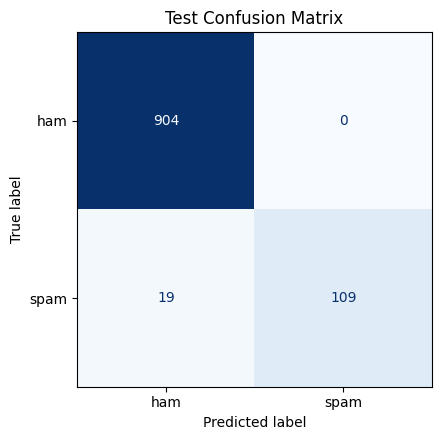

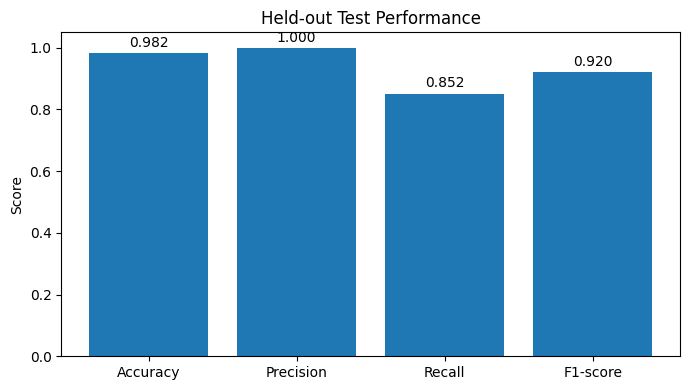

In [12]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['ham', 'spam']).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False
)
ax.set_title('Test Confusion Matrix')
fig.tight_layout()
fig.savefig(OUT / 'confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

names = ['Accuracy', 'Precision', 'Recall', 'F1-score']
values = [metrics['accuracy'], metrics['precision_spam'],
          metrics['recall_spam'], metrics['f1_spam']]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(names, values)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Held-out Test Performance')
for i, value in enumerate(values):
    ax.text(i, value + 0.02, f'{value:.3f}', ha='center')
fig.tight_layout()
fig.savefig(OUT / 'performance_metrics.png', dpi=180, bbox_inches='tight')
plt.show()

## 8. Show 10 example predictions

The examples below come from the held-out test set. The confidence score is the model's estimated probability for its chosen class, **not a guarantee of correctness**.

,message,actual_label,predicted_label,confidence,spam_probability
0,Can you plz tell me the ans. BSLVYL sent via f...,ham,ham,0.938112,0.061888
1,You intrepid duo you! Have a great time and se...,ham,ham,0.985372,0.014628
2,R u in this continent?,ham,ham,0.875424,0.124576
3,"Cool, want me to go to kappa or should I meet ...",ham,ham,0.995228,0.004772
4,I'm meeting Darren...,ham,ham,0.986488,0.013512
5,it to 80488. Your 500 free text messages are v...,spam,spam,0.958350,0.958350
6,* FREE* POLYPHONIC RINGTONE Text SUPER to 8713...,spam,spam,0.973020,0.973020
7,Freemsg: 1-month unlimited free calls! Activat...,spam,spam,0.932325,0.932325
8,Join the UK's horniest Dogging service and u c...,spam,spam,0.986092,0.986092
9,YOU ARE CHOSEN TO RECEIVE A £350 AWARD! Pls ca...,spam,spam,0.983448,0.983448


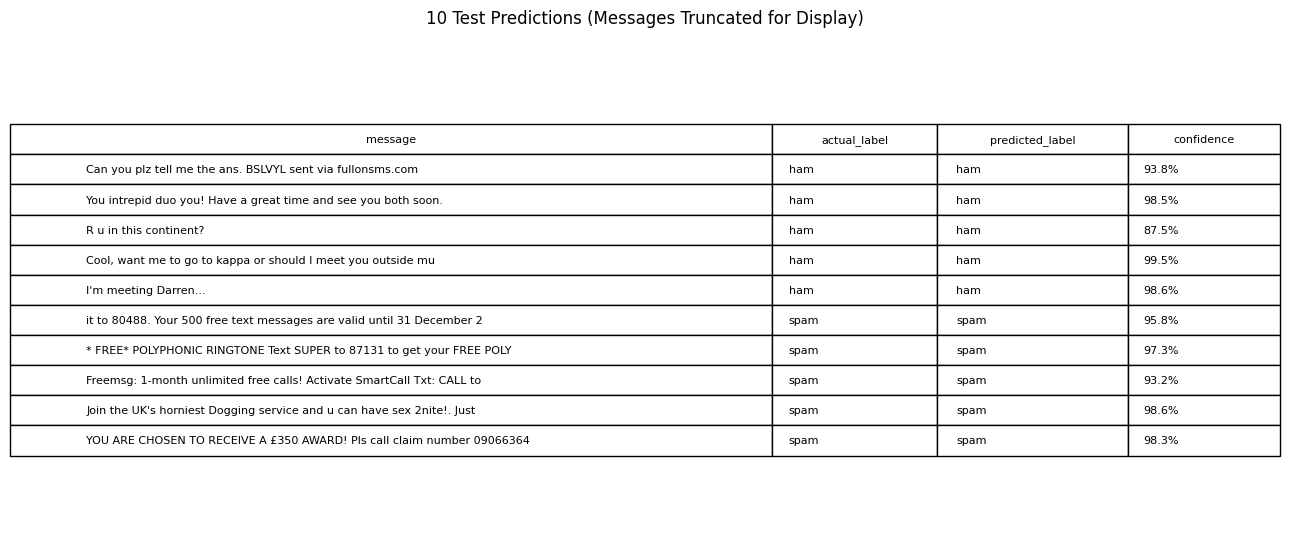

In [13]:
examples = pd.DataFrame({
    'message': X_test.reset_index(drop=True),
    'actual': y_test.reset_index(drop=True),
    'predicted': y_pred,
    'spam_probability': y_prob
})
examples['actual_label'] = examples['actual'].map({0: 'ham', 1: 'spam'})
examples['predicted_label'] = examples['predicted'].map({0: 'ham', 1: 'spam'})
examples['confidence'] = np.where(
    examples['predicted'].eq(1), examples['spam_probability'],
    1 - examples['spam_probability']
)

# Include examples of both classes where available.
example_ham = examples[examples['actual'] == 0].head(5)
example_spam = examples[examples['actual'] == 1].head(5)
ten_examples = pd.concat([example_ham, example_spam], ignore_index=True)
ten_examples = ten_examples[['message', 'actual_label', 'predicted_label', 'confidence', 'spam_probability']]
display(ten_examples)
ten_examples.to_csv(OUT / '10_example_predictions.csv', index=False)

# Save a readable table image too.
view = ten_examples.copy()
view['message'] = view['message'].str.slice(0, 70).str.replace('\n', ' ', regex=False)
view['confidence'] = view['confidence'].map(lambda p: f'{p:.1%}')
view = view[['message', 'actual_label', 'predicted_label', 'confidence']]
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.axis('off')
table = ax.table(cellText=view.values, colLabels=view.columns, loc='center', cellLoc='left',
                 colWidths=[0.60, 0.13, 0.15, 0.12])
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.6)
ax.set_title('10 Test Predictions (Messages Truncated for Display)', pad=20)
fig.tight_layout()
fig.savefig(OUT / '10_example_predictions.png', dpi=180, bbox_inches='tight')
plt.show()

## 9. Save the model and try new messages

The saved `spam_classifier.joblib` file contains both TF-IDF processing and the trained classifier. Load it to make predictions without retraining. **Only load joblib files from trusted sources.**

In [14]:
model_path = OUT / 'spam_classifier.joblib'
joblib.dump(model, model_path)
loaded_model = joblib.load(model_path)

new_messages = [
    'Congratulations! You have won a prize. Claim it now!',
    'Are we still meeting at the library at 4 pm?',
    'URGENT! Your account won cash, call this number to claim.',
    'Please send me the lecture notes when you have time.'
]
new_pred = loaded_model.predict(new_messages)
new_probs = loaded_model.predict_proba(new_messages)
new_results = pd.DataFrame({
    'message': new_messages,
    'predicted_label': ['spam' if p == 1 else 'ham' for p in new_pred],
    'confidence': [float(new_probs[i, p]) for i, p in enumerate(new_pred)]
})
display(new_results)
new_results.to_csv(OUT / 'new_message_predictions.csv', index=False)
print('Saved:', model_path)

,message,predicted_label,confidence
0,Congratulations! You have won a prize. Claim i...,spam,0.984785
1,Are we still meeting at the library at 4 pm?,ham,0.978327
2,"URGENT! Your account won cash, call this numbe...",spam,0.863277
3,Please send me the lecture notes when you have...,ham,0.969793


Saved: outputs/spam_classifier.joblib


## 10. Package deliverables and download


In [15]:
import shutil
archive_name = shutil.make_archive('task2_outputs', 'zip', root_dir='.', base_dir='outputs')
print('Created:', archive_name)
print('\nOutput files:')
for path in sorted(OUT.iterdir()):
    print(f' - {path.name} ({path.stat().st_size / 1024:.1f} KB)')

from google.colab import files
files.download('task2_outputs.zip')

Created: /content/task2_outputs.zip

Output files:
 - 10_example_predictions.csv (1.4 KB)
 - 10_example_predictions.png (147.6 KB)
 - classification_report.txt (0.3 KB)
 - confusion_matrix.png (26.4 KB)
 - dataset_sample.csv (2.3 KB)
 - metrics.json (0.3 KB)
 - new_message_predictions.csv (0.3 KB)
 - performance_metrics.png (35.1 KB)
 - spam_classifier.joblib (296.5 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>